In [1]:
import requests
import pandas as pd
import networkx as nx

# city: (Latitude, Longitude)
location = {
    "Ulaanbaatar": (47.9188, 106.9176),
    "Altai": (46.3722, 96.2583),
    "Arvaikheer": (46.2639, 102.7750),
    "Baruun-Urt": (46.6806, 113.2792),
    "Bayankhongor": (46.1167, 100.7167),
    "Bulgan": (48.8125, 103.5347),
    "Dalanzadgad": (43.5708, 104.4250),
    "Darkhan": (49.4867, 105.9228),
    "Zuunmod": (47.7069, 106.9750),
    "Mandalgovi": (45.7625, 106.2708),
    "Murun": (49.6342, 100.1625),
    "Sainshand": (44.8911, 110.1367),
    "Sukhbaatar": (50.2314, 106.2081),
    "Ulaangom": (50.0306, 92.0667),
    "Uliastai": (47.7417, 96.8444),
    "Khovd": (48.0056, 91.6300),
    "Tsetserleg": (47.4750, 101.4542),
    "Choibalsan": (48.0797, 114.5342),
    "Choir": (46.3611, 108.3611),
    "Ulgii": (48.9706, 89.9656),
    "Chinggis City": (47.3167, 110.6500),
    "Erdenet": (49.0278, 104.0450)
}

# prep in long, lat format
city_names = list(location.keys())
coordinates_list = []

for city in city_names:
    lat = location[city][0]
    lon = location[city][1]
    coordinates_list.append(f"{lon},{lat}")

# join all coordinates with a semicolon as required by OSRM
coords_string = ";".join(coordinates_list)

# add '?annotations=distance' to get distances instead of travel times
url = f"http://router.project-osrm.org/table/v1/driving/{coords_string}?annotations=distance"

response = requests.get(url)

if response.status_code == 200:
    data = response.json()
    
    #convert m to km
    distances_meters = data['distances']
    distances_km = []
    for row in distances_meters:
        row_km = [round(meters / 1000, 1) for meters in row]
        distances_km.append(row_km)
        
    df_distance_matrix = pd.DataFrame(distances_km, index=city_names, columns=city_names)
    #print(df_distance_matrix)
else:
    print(f"error: {response.status_code}")
    print(response.text)

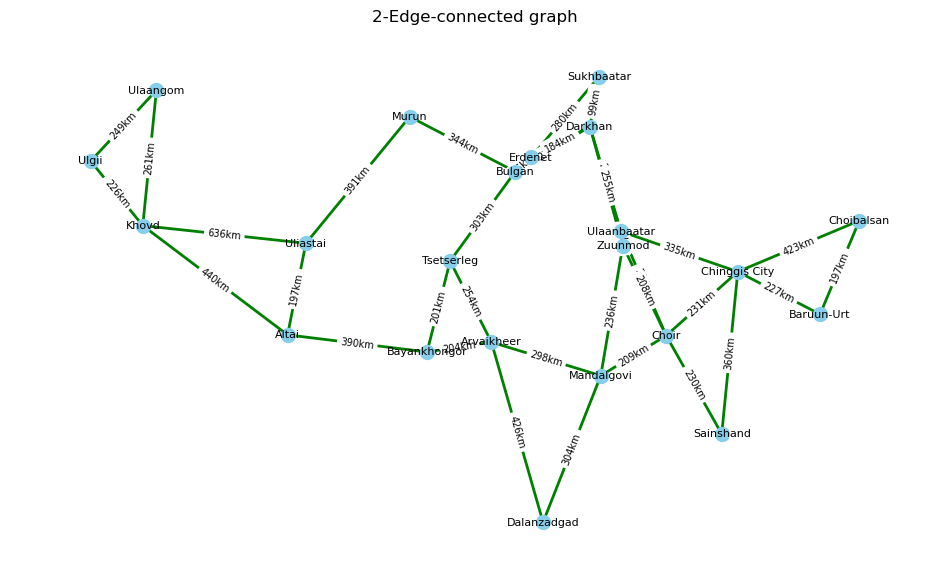

In [15]:
import csv
import matplotlib.pyplot as plt
import networkx as nx
from flask import Flask, request, jsonify
import json


def draw_graph(graph, title="Graph"):
    pos = {city: (lon, lat) for city, (lat, lon) in location.items()}
    plt.figure(figsize=(12, 7))
    nx.draw_networkx_nodes(graph, pos, node_color="skyblue", node_size=100)
    nx.draw_networkx_edges(graph, pos, edge_color="green", width=2)
    nx.draw_networkx_labels(graph, pos, font_family="sans-serif", font_size=8)
    
    edge_labels = nx.get_edge_attributes(graph, "weight")
    formatted_edge_labels = {edge: f"{weight:.0f}km" for edge, weight in edge_labels.items()}
    nx.draw_networkx_edge_labels(graph, pos, edge_labels=formatted_edge_labels, font_size=7)
    
    plt.title(title)
    plt.axis("off")
    plt.show()

location = {
    "Ulaanbaatar": (47.9188, 106.9176),
    "Altai": (46.3722, 96.2583),
    "Arvaikheer": (46.2639, 102.7750),
    "Baruun-Urt": (46.6806, 113.2792),
    "Bayankhongor": (46.1167, 100.7167),
    "Bulgan": (48.8125, 103.5347),
    "Dalanzadgad": (43.5708, 104.4250),
    "Darkhan": (49.4867, 105.9228),
    "Zuunmod": (47.7069, 106.9750),
    "Mandalgovi": (45.7625, 106.2708),
    "Murun": (49.6342, 100.1625),
    "Sainshand": (44.8911, 110.1367),
    "Sukhbaatar": (50.2314, 106.2081),
    "Ulaangom": (50.0306, 92.0667),
    "Uliastai": (47.7417, 96.8444),
    "Khovd": (48.0056, 91.6300),
    "Tsetserleg": (47.4750, 101.4542),
    "Choibalsan": (48.0797, 114.5342),
    "Choir": (46.3611, 108.3611),
    "Ulgii": (48.9706, 89.9656),
    "Chinggis City": (47.3167, 110.6500),
    "Erdenet": (49.0278, 104.0450)
}

cities_graph = nx.Graph()
lookup_dict = {}
edges = []

with open("distance_matrix.csv", mode="r", encoding="utf-8") as file:
    reader = csv.reader(file)
    header = next(reader)
    for row in reader:
        origin_city = row[0]
        lookup_dict[origin_city] = {}
        for i in range(1, len(row)):
            destination_city = header[i]
            distance = float(row[i])
            lookup_dict[origin_city][destination_city] = distance
            if origin_city != destination_city:
                edges.append((origin_city, destination_city, distance))

cities_graph.add_weighted_edges_from(edges)
#draw_graph(cities_graph, "full mesh graph")

mst_graph = nx.minimum_spanning_tree(cities_graph, algorithm="prim")
#draw_graph(mst_graph, "MST graph")

two_edge_connected_graph = mst_graph.copy()
unused_edges = []
for u, v, data in cities_graph.edges(data=True):
    if not two_edge_connected_graph.has_edge(u, v):
        unused_edges.append((u, v, data["weight"]))
#sort by weight (x[2])
unused_edges.sort(key=lambda x: x[2])

for u, v, weight in unused_edges:
    current_bridges = list(nx.bridges(two_edge_connected_graph))
    if not current_bridges:
        break
    two_edge_connected_graph.add_edge(u, v, weight=weight)
    
    new_bridges = list(nx.bridges(two_edge_connected_graph))
    if len(new_bridges) >= len(current_bridges):
        two_edge_connected_graph.remove_edge(u, v)


draw_graph(two_edge_connected_graph, "2-Edge-connected graph")
# EXPORT
with open('mesh_graph.json', 'w') as f:
    json.dump(nx.node_link_data(cities_graph), f)

with open('two_edge_graph.json', 'w') as f:
    json.dump(nx.node_link_data(two_edge_connected_graph), f)

with open('mst_graph.json', 'w') as f:
    json.dump(nx.node_link_data(mst_graph), f)


 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [14/Oct/2026 11:29:10] "POST /api/network/simulate-cut/ HTTP/1.1" 200 -
127.0.0.1 - - [14/Oct/2026 11:29:52] "POST /api/network/simulate-cut/ HTTP/1.1" 200 -
127.0.0.1 - - [14/Oct/2026 11:30:00] "POST /api/network/simulate-cut/ HTTP/1.1" 200 -
127.0.0.1 - - [14/Oct/2026 11:31:35] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [14/Oct/2026 11:31:35] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [14/Oct/2026 11:31:56] "GET /api/network/topology/two_edge HTTP/1.1" 200 -
127.0.0.1 - - [14/Oct/2026 11:31:56] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [14/Oct/2026 11:32:27] "POST /api/network/simulate-cut/ HTTP/1.1" 200 -
127.0.0.1 - - [14/Oct/2026 11:32:35] "POST /api/network/simulate-cut/ HTTP/1.1" 200 -
127.0.0.1 - - [14/Oct/2026 11:32:43] "GET /api/network/topology/two_edge HTTP/1.1" 200 -
127.0.0.1 - - [14/Oct/2026 11:32:43] "GET /favicon.ico HTTP/1.1" 404 -
